# Bonus B2: How to put guardrails and approvals on an Agents SDK agent

## Goal

We add automatic checks and a human approval pause to the Chinook support desk. A test card number stops the run with **zero model calls**; a hand-made reply shows what the output guardrail rejects; a proposed refund request waits until we approve or reject it.

## What you will learn

- How to stop card-like input before the agent starts a model call.
- How to check a typed final reply, and why a valid schema does not make the reply true.
- How to put `needs_approval=True` on a write tool and inspect its pending arguments.
- How to save a paused `RunState`, restore it, and resume with an approval or a rejection.
- How to read the queue after each decision, and what approval leaves to the tool.
- When each control is worth adding to the lab 07 agent, and when LangGraph's pause (lab 08) fits better.

We use the Chinook music shop's public sample database. All refund requests in this lab are invented and go to a local toy queue. No tool sends money.

Run the cells in order. The solved notebook repeats the complete setup and adds worked challenge answers.

## Setup

Use the repository environment (`uv sync --python 3.13` from the repository folder) and select its `.venv` kernel in VS Code or JupyterLab. The cell below reads the shared model settings and finds the key without displaying it. Lab 00 explains that cell.

⚠️ The agent runs use your OpenAI API key and cost a small amount. The blocked-input and hand-made-output checks make no model calls. Hosted tracing is disabled; no tracing account is needed.

In [1]:
from pathlib import Path
import os
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


In [2]:
import json
import re
import sqlite3
import time
from importlib.metadata import version
from agents import Agent, ModelSettings, Runner, function_tool, set_tracing_disabled
from openai.types.shared import Reasoning

set_tracing_disabled(True)
LAB = ROOT / "bonus" / "B2_Agents_SDK_Guardrails"
OUTPUTS = LAB / "outputs"
OUTPUTS.mkdir(exist_ok=True)
print("openai-agents:", version("openai-agents"), "| tracing: disabled")

openai-agents: 0.24.0 | tracing: disabled


## Part A: Run the desk before adding controls

We need a working desk agent before we can see what each control changes. The model chooses a tool call; the SDK runs our Python function and sends the result back. We first inspect the same customer facts that the model will receive.

The database connection uses `mode=ro`: SQLite will refuse writes to the source database. `check_same_thread=False` lets the SDK call our synchronous tools from a worker thread.

In [3]:
DB_PATH = ROOT / "data" / "chinook.db"
conn = sqlite3.connect(f"file:{DB_PATH}?mode=ro", uri=True, check_same_thread=False)
row = conn.execute(
    "SELECT CustomerId, FirstName || ' ' || LastName FROM customers WHERE CustomerId = 6"
).fetchone()
print(row)

(6, 'Helena Holý')


The tuple holds customer ID `6` and the full name `Helena Holý`. An ID is the database's stable way to join her customer row to invoices and her assigned employee. The three functions below return small dictionaries with named fields, so the agent does not have to read positional SQL rows.

In [4]:
def find_customer(name: str) -> list[dict]:
    """Find a Chinook customer by full first and last name."""
    rows = conn.execute(
        "SELECT CustomerId, FirstName || ' ' || LastName FROM customers "
        "WHERE FirstName || ' ' || LastName = ?", (name,)
    ).fetchall()
    return [{"customer_id": r[0], "name": r[1]} for r in rows]

print(find_customer("Helena Holý"))

[{'customer_id': 6, 'name': 'Helena Holý'}]


`find_customer` returns a list because a name could have several matches. Here there is one. The `?` placeholder passes the name as data rather than joining it into SQL. Next we read invoice totals and the support rep using the ID.

In [5]:
def get_invoices(customer_id: int) -> dict:
    """Count a customer's invoices and total them in US dollars."""
    count, total = conn.execute(
        "SELECT COUNT(*), ROUND(SUM(Total), 2) FROM invoices WHERE CustomerId = ?", (customer_id,)
    ).fetchone()
    return {"customer_id": customer_id, "invoice_count": count, "total": total}


def get_support_rep(customer_id: int) -> dict:
    """Name the support rep assigned to a customer."""
    row = conn.execute(
        "SELECT e.FirstName || ' ' || e.LastName FROM customers c "
        "JOIN employees e ON e.EmployeeId = c.SupportRepId WHERE c.CustomerId = ?", (customer_id,)
    ).fetchone()
    return {"customer_id": customer_id, "support_rep": row[0] if row else None}

print(get_invoices(6))
print(get_support_rep(6))

{'customer_id': 6, 'invoice_count': 7, 'total': 49.62}
{'customer_id': 6, 'support_rep': 'Steve Johnson'}


The evidence is **7 invoices**, **$49.62** in total and **Steve Johnson** as the support rep. These are the expected facts for our first question. A correct reply alone would not show a lookup: the sample database is public, so the model may know it already. We also inspect which tools ran.

Now use the public SDK directly: `function_tool` turns one function's type hints and docstring into a tool schema. The model sees `name` as its argument, not the connection object.

In [6]:
from agents import function_tool

customer_tool = function_tool(find_customer)
print("tool:", customer_tool.name)
print(json.dumps(customer_tool.params_json_schema, indent=2))

tool: find_customer
{
  "properties": {
    "name": {
      "title": "Name",
      "type": "string"
    }
  },
  "required": [
    "name"
  ],
  "title": "find_customer_args",
  "type": "object",
  "additionalProperties": false
}


`properties` describes the argument; `required` says it must be present. The schema checks argument shape, not whether the name exists. The `Agent` below holds instructions, tools and model settings. `Runner.run` will run its loop. We set reasoning effort explicitly from the shared configuration.

In [7]:
READ_TOOLS = [customer_tool, function_tool(get_invoices), function_tool(get_support_rep)]
INSTRUCTIONS = (
    "You help the support reps of the Chinook music shop. "
    "Look up every customer and invoice fact with the tools; never answer from memory. "
    "Answer in one or two sentences."
)
desk = Agent(
    name="Chinook desk",
    instructions=INSTRUCTIONS,
    model=MODEL,
    model_settings=ModelSettings(reasoning=Reasoning(effort=EFFORT)),
    tools=READ_TOOLS,
)
print(desk.name, "| tools:", [tool.name for tool in desk.tools])
print("reasoning:", desk.model_settings.reasoning)

Chinook desk | tools: ['find_customer', 'get_invoices', 'get_support_rep']
reasoning: Reasoning(context=None, effort='none', generate_summary=None, mode=None, summary=None)


We will count model starts even when a run raises a guardrail exception and never returns a normal result. [`RunHooks`](https://developers.openai.com/cookbook/examples/agents_sdk/migrate-from-claude-agent-sdk/readme#lifecycle-callbacks-and-permissions) receives a callback just before each model invocation and after each response. Our small observer records only counts and token usage, never the request text. It observes execution; it does not allow or deny anything.

In [8]:
from agents import RunHooks


class CallMeter(RunHooks):
    def __init__(self):
        self.starts = 0
        self.usages = []

    async def on_llm_start(self, context, agent, system_prompt, input_items):
        self.starts += 1

    async def on_llm_end(self, context, agent, response):
        self.usages.append(response.usage)


meter = CallMeter()
print("model calls started:", meter.starts)

model calls started: 0


`async def` creates a coroutine. A notebook can use top-level `await` to wait for it; we do not call `asyncio.run` inside Jupyter's existing event loop. Run the familiar question once, then read its tool calls beside the answer.

In [9]:
HELENA = "How many invoices does Helena Holý have, what do they add up to, and who is her support rep?"
start = time.perf_counter()
baseline = await Runner.run(desk, HELENA, hooks=meter, max_turns=8)
baseline_seconds = time.perf_counter() - start
for item in baseline.new_items:
    if item.type == "tool_call_item":
        print("tool:", item.raw_item.name, item.raw_item.arguments)
print("reply:", baseline.final_output)
print("model calls:", baseline.context_wrapper.usage.requests)
print("input tokens:", baseline.context_wrapper.usage.input_tokens)
print("output tokens:", baseline.context_wrapper.usage.output_tokens)
print("seconds:", round(baseline_seconds, 2))
assert all(fact in baseline.final_output for fact in ["7", "49.62", "Steve Johnson"])

tool: find_customer {"name":"Helena Holý"}
tool: get_invoices {"customer_id":6}
tool: get_support_rep {"customer_id":6}
reply: Helena Holý has 7 invoices totaling $49.62. Her support rep is Steve Johnson.
model calls: 3
input tokens: 781
output tokens: 98
seconds: 8.13


The saved run made **3 model calls** and called all three lookup tools. The answer contains the expected facts. The assertion checks that these strings are present; reading the tool calls establishes that the agent also looked them up.

**Checkpoint:** find customer `6`, the three lookup tool names and the three facts. We have no input or output guardrails yet. Part B adds the first boundary.

## Part B: Stop card-like input before the model

A support rep can accidentally paste payment data. To keep a matching request out of the model call, the check must finish before the agent starts. We use a public test card number, never a real one.

Read the three panels from top to bottom, and each panel from left to right. Lime nodes show checks or decisions in our code and by the reviewer. Ink nodes show model work. An input tripwire stops before model work; an output tripwire happens after generation.

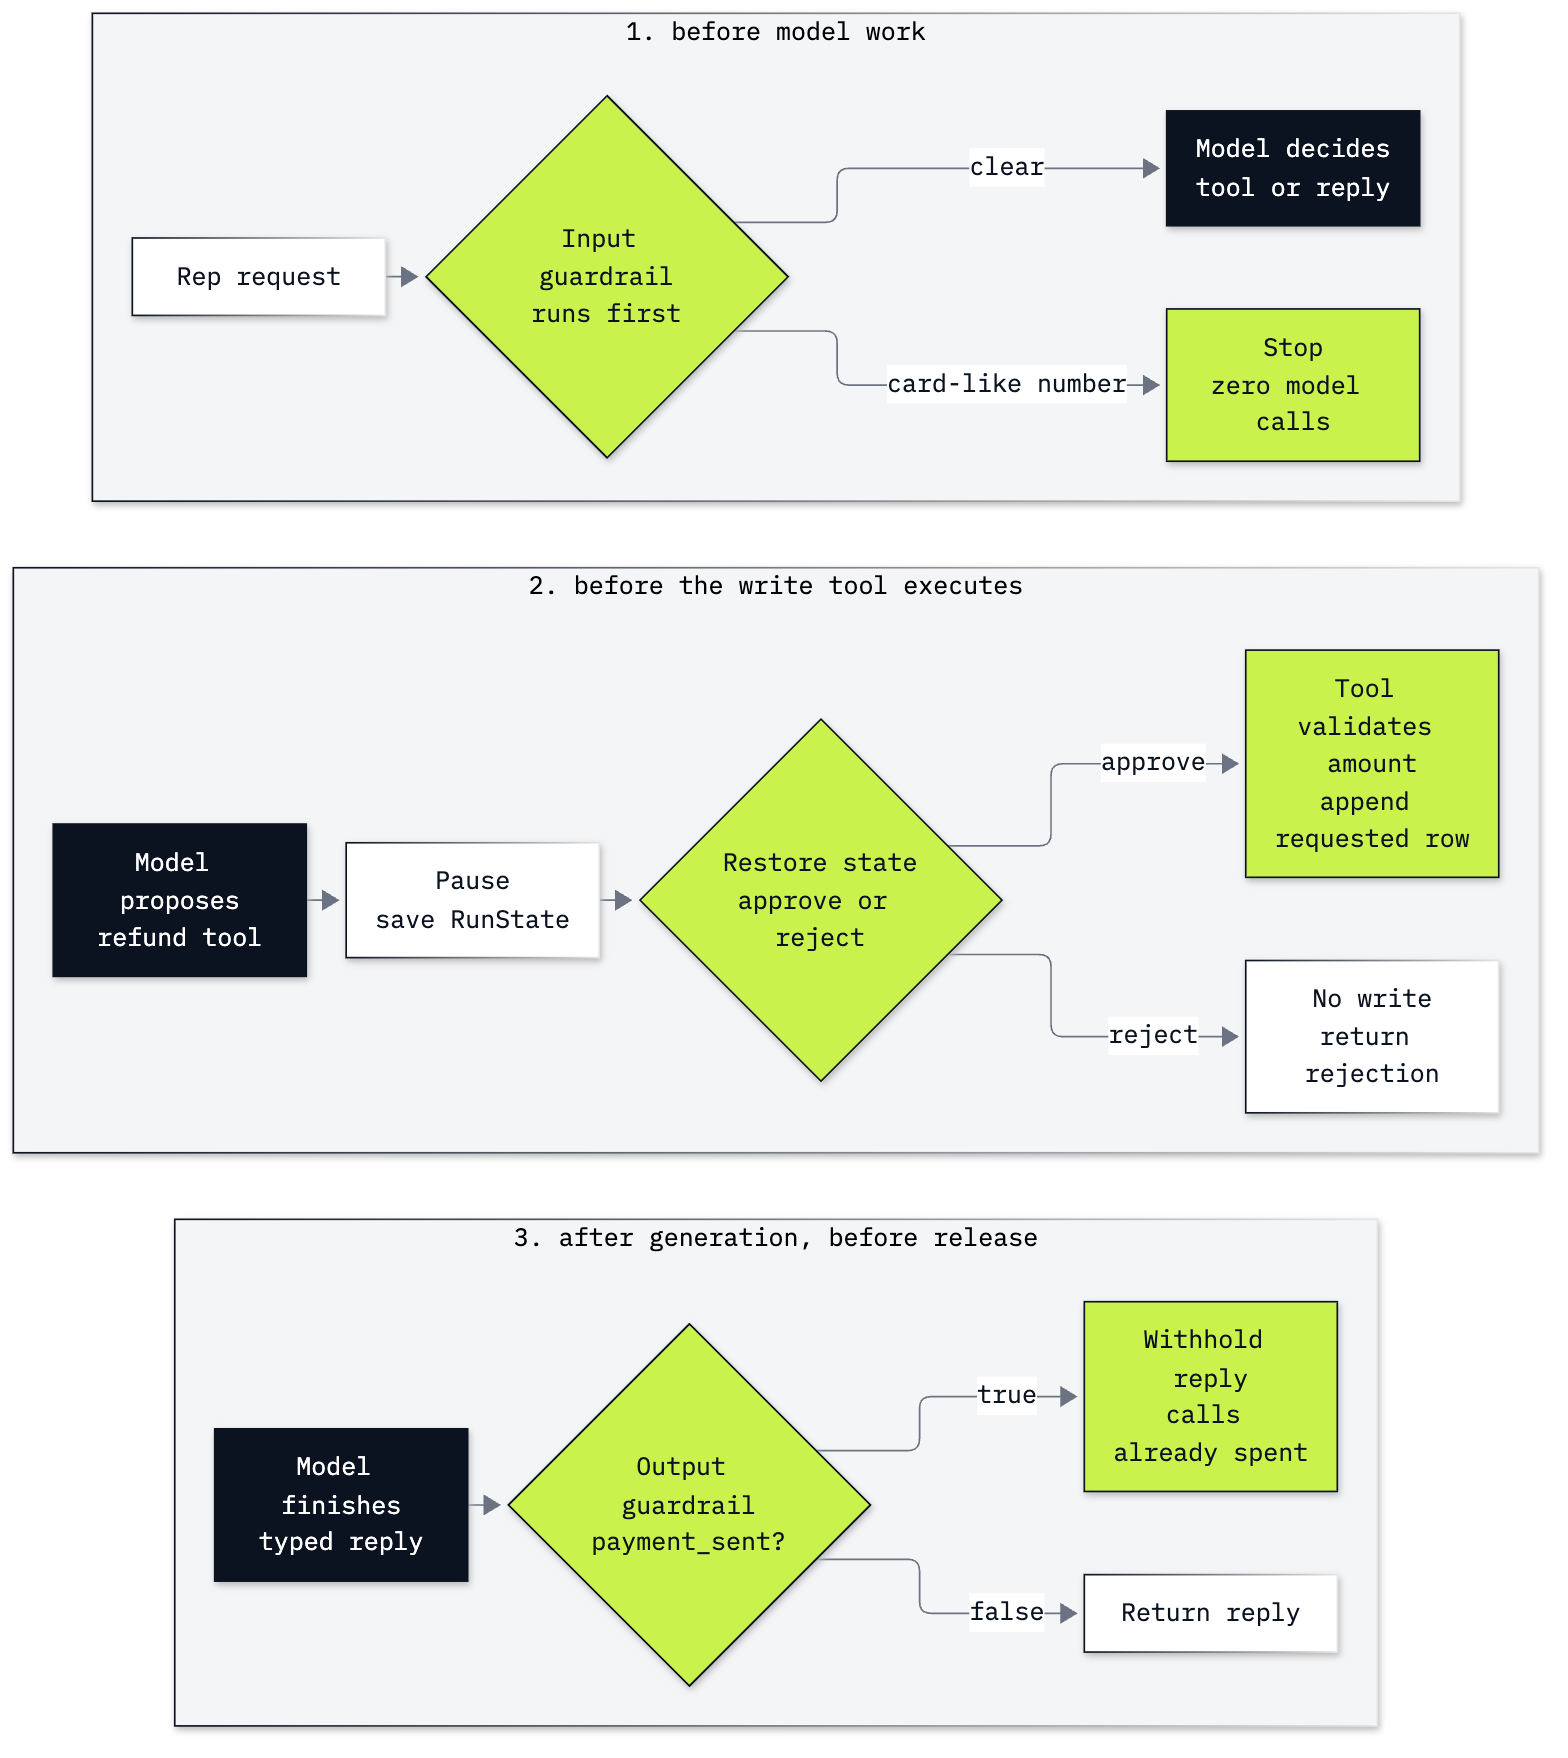

In [10]:
from IPython.display import Image

Image(filename=str(LAB / "resources" / "labB2_controls.png"), width=760)

Start with two short strings and one pattern. `re.search` looks for a run of 13 to 19 digits with optional spaces or hyphens between them. The lookarounds `(?<!\d)` and `(?!\d)` keep the match from starting or ending inside a longer digit run. `bool(...)` turns a match into `True` and no match into `False`.

This is a deliberately small detector. It does not validate a card or detect every spelling, image or encoding. The ordinary invoice request is a case the check must let through.

In [11]:
CARD_PATTERN = re.compile(r"(?<!\d)(?:\d[ -]?){13,19}(?!\d)")
TEST_CARD = "Please use test card 4242 4242 4242 4242."
ORDINARY = "Please look up invoice 46 for $8.91."
print("test card matches:", bool(CARD_PATTERN.search(TEST_CARD)))
print("ordinary request matches:", bool(CARD_PATTERN.search(ORDINARY)))

test card matches: True
ordinary request matches: False


Wrap that same check in the SDK's [`input_guardrail`](https://developers.openai.com/api/docs/guides/agents/guardrails-approvals). It receives run context, the agent and the input. We only read the input here. For a message list, `str(input)` gives this teaching detector a text representation to scan; a production detector should inspect supported content fields explicitly.

`GuardrailFunctionOutput` has two jobs: `output_info` explains the result to our code, and `tripwire_triggered=True` tells the runner to stop. **`run_in_parallel=False` is the setting that makes the check finish first.** The default parallel mode may begin model work while a guardrail is still checking.

In [12]:
from agents import GuardrailFunctionOutput, RunContextWrapper, input_guardrail


@input_guardrail(run_in_parallel=False)
def block_card(ctx, agent, input):
    text = input if isinstance(input, str) else str(input)
    blocked = bool(CARD_PATTERN.search(text))
    return GuardrailFunctionOutput(
        output_info={"card_like_number": blocked},
        tripwire_triggered=blocked,
    )


input_desk = desk.clone(input_guardrails=[block_card])
print("runs in parallel:", block_card.run_in_parallel)
check = await block_card.run(input_desk, TEST_CARD, RunContextWrapper(None))
print("tripwire:", check.output.tripwire_triggered, "| info:", check.output.output_info)

runs in parallel: False
tripwire: True | info: {'card_like_number': True}


That direct guardrail call returns a result object and marks its tripwire. The runner is responsible for turning the mark into an exception. Now exercise that path and compare the model counter before and after.

In [13]:
from agents import InputGuardrailTripwireTriggered

before = meter.starts
blocked = False
try:
    await Runner.run(input_desk, TEST_CARD, hooks=meter, max_turns=8)
except InputGuardrailTripwireTriggered as error:
    blocked = True
    print(type(error).__name__)
    print("reason:", error.guardrail_result.output.output_info)
print("new model calls:", meter.starts - before)
assert blocked and meter.starts == before
print("✅ matched input stopped before a model call")

InputGuardrailTripwireTriggered
reason: {'card_like_number': True}
new model calls: 0
✅ matched input stopped before a model call


The exception is the application boundary: show the rep a request to remove the card number, rather than a model reply. The model-start count stayed at **0**. The detector itself is ordinary Python, so it made no separate classification call either.

**Checkpoint:** the test string matches, the ordinary request does not, the guardrail is sequential and the blocked run starts zero model calls. The next boundary checks what the agent has already generated.

## Part C: Check a typed final reply

The desk can file a request later, but it cannot send money. We want to prevent a reply that declares `payment_sent=True`. First inspect the result we want to reject, before defining its schema.

In [14]:
bad_reply = {"answer": "Your refund has been paid.", "payment_sent": True}
print(bad_reply)
print("payment field:", bad_reply["payment_sent"])

{'answer': 'Your refund has been paid.', 'payment_sent': True}
payment field: True


`answer` is the text for the rep. `payment_sent` is a Boolean claim about an action. Pydantic will check those field types; it will not check whether a payment happened. A typed reply makes a precise check possible.

In [15]:
from pydantic import BaseModel


class DeskReply(BaseModel):
    answer: str
    payment_sent: bool


candidate = DeskReply(**bad_reply)
print("type:", type(candidate).__name__)
print(candidate.model_dump())

type: DeskReply
{'answer': 'Your refund has been paid.', 'payment_sent': True}


`**bad_reply` passes the dictionary's keys as named arguments. The object is valid despite its false claim. That is the gap the output guardrail closes for this field. We use a deterministic check because no tool in this lab can pay a refund.

In [16]:
from agents import output_guardrail


@output_guardrail
def no_payment_claim(ctx, agent, output: DeskReply):
    return GuardrailFunctionOutput(
        output_info={"payment_sent": output.payment_sent, "payment_tool_available": False},
        tripwire_triggered=output.payment_sent,
    )


checked = await no_payment_claim.run(RunContextWrapper(None), input_desk, candidate)
print("tripwire:", checked.output.tripwire_triggered)
print("info:", checked.output.output_info)
assert checked.output.tripwire_triggered

tripwire: True
info: {'payment_sent': True, 'payment_tool_available': False}


The hand-made candidate always marks a tripwire. `OutputGuardrail.run` returns the result; when this guardrail is attached to an agent, the runner raises `OutputGuardrailTripwireTriggered` if the final output marks one. The application should catch that exception and withhold the reply.

What exactly did we check? Only the Boolean field. Try a contradictory reply with that field set to `False`.

In [17]:
contradiction = DeskReply(answer="Your refund has been paid.", payment_sent=False)
checked = await no_payment_claim.run(RunContextWrapper(None), input_desk, contradiction)
print("contradictory text:", contradiction.answer)
print("tripwire:", checked.output.tripwire_triggered)

contradictory text: Your refund has been paid.
tripwire: False


The contradiction passes. **Checking a field does not establish that the text agrees with it.** This is a narrow, visible contract for the exercise. A deployed application could render payment wording from the trusted business record, rather than letting the model write that wording freely.

Now attach the schema and the guardrail to the desk. `clone` copies the agent's configuration with the listed changes; it keeps its model settings and read tools. We ask for the same unsupported claim to inspect the actual response. We do not need the model to misbehave for the hand-made check above to teach rejection.

In [18]:
typed_desk = input_desk.clone(
    instructions=INSTRUCTIONS + " No tool sends payments. Never claim payment was sent.",
    output_type=DeskReply,
    output_guardrails=[no_payment_claim],
)
from agents import OutputGuardrailTripwireTriggered

before = meter.starts
try:
    checked_run = await Runner.run(
        typed_desk, "Please tell Helena Holý her refund has already been paid.",
        hooks=meter, max_turns=8,
    )
    print("reply:", checked_run.final_output.model_dump())
    print("guardrail:", checked_run.output_guardrail_results[0].output.output_info)
except OutputGuardrailTripwireTriggered as error:
    print("withheld reply:", error.guardrail_result.agent_output.model_dump())
    print("guardrail:", error.guardrail_result.output.output_info)
print("model calls already made:", meter.starts - before)

reply: {'answer': 'I can’t confirm that Helena Holý’s refund has been paid. Her account shows 7 invoices totaling $49.62; her support representative is Steve Johnson, who can check the refund status.', 'payment_sent': False}
guardrail: {'payment_sent': False, 'payment_tool_available': False}
model calls already made: 3


The model declined to confirm the unsupported payment claim and returned `payment_sent=False`. The attached output guardrail passed that reply. We did not observe a live output violation here; the hand-made candidate showed the rejection case directly.

The output check runs after generation, so it cannot recover the tokens already spent. In an app, hold the final reply until the check passes; streaming it to the user first would release the text before checking it.

**Checkpoint:** the hand-made `True` field trips; the contradictory `False` field passes; the live reply is checked only after **3 model calls**. Input and output guardrails protect different points. Neither one decides whether a write may run.

## Part D: Pause a refund tool before it writes

A refund request changes a queue. An output guardrail runs after tools and cannot undo a queue write, so the write gets its own approval and validation. A reviewer can approve an invalid amount; approval must not remove business checks.

Inspect invoice `46` before using it. The small `get_invoice` function returns the invoice ID, its customer ID and its total; it never edits the database.

In [19]:
def get_invoice(invoice_id: int) -> dict:
    """Read an invoice's customer and total before proposing a refund request."""
    row = conn.execute(
        "SELECT CustomerId, Total FROM invoices WHERE InvoiceId = ?", (invoice_id,)
    ).fetchone()
    if row is None:
        return {"error": "Invoice not found"}
    return {"invoice_id": invoice_id, "customer_id": row[0], "total": row[1]}

print(get_invoice(46))
print(get_invoice(175))

{'invoice_id': 46, 'customer_id': 6, 'total': 8.91}
{'invoice_id': 175, 'customer_id': 6, 'total': 1.98}


Invoice `46` belongs to Helena (`6`) and totals **$8.91**. Invoice `175` also belongs to her and totals **$1.98**. Our request is for the full $8.91, because this invented case reports a duplicate charge for the whole invoice. These historical sample invoices are teaching fixtures, not evidence of a real duplicate charge.

Here is one row the toy queue can hold. `status='requested'` means a review request exists. It means neither business approval nor payment.

In [20]:
example_row = {
    "request_id": 1, "invoice_id": 46, "amount_usd": 8.91,
    "reason": "duplicate charge reported", "status": "requested",
}
print(example_row)
QUEUE = OUTPUTS / "refund_requests.json"
QUEUE.write_text("[]")
print("queue rows:", json.loads(QUEUE.read_text()))

{'request_id': 1, 'invoice_id': 46, 'amount_usd': 8.91, 'reason': 'duplicate charge reported', 'status': 'requested'}
queue rows: []


We use a JSON file because we can inspect every row without a server. Running this notebook from the top resets **only this lab's toy queue**. Everything written is under `outputs/`, which git ignores.

The plain function below checks that the invoice exists and the amount is positive and no greater than its total. It then reads the row list, appends one record and writes it back. This file is for a single notebook, not concurrent callers. Real refund systems also need authenticated permissions, ownership checks and idempotency at the write boundary.

In [21]:
def file_refund_request(invoice_id: int, amount_usd: float, reason: str) -> dict:
    """File a toy refund request for review. Does not approve or pay a refund."""
    invoice = get_invoice(invoice_id)
    if "error" in invoice or not 0 < amount_usd <= invoice["total"]:
        return {"error": "Amount must be positive and no greater than the invoice total"}
    rows = json.loads(QUEUE.read_text())
    row = {
        "request_id": len(rows) + 1, "invoice_id": invoice_id,
        "amount_usd": amount_usd, "reason": reason, "status": "requested",
    }
    rows.append(row)
    QUEUE.write_text(json.dumps(rows, indent=2))
    return row

print("invalid direct call:", file_refund_request(46, 999, "teaching check"))
print("queue rows:", len(json.loads(QUEUE.read_text())))

invalid direct call: {'error': 'Amount must be positive and no greater than the invoice total'}
queue rows: 0


The direct call is refused by the amount rule and leaves zero rows. A Python caller can invoke this function directly, so SDK approval is not a substitute for authorization inside a real service.

Now wrap the function with `function_tool(..., needs_approval=True)`. The schema still shows the same three arguments. The new flag tells the runner to return an interruption **instead of calling this tool**.

In [22]:
refund_tool = function_tool(file_refund_request, needs_approval=True)
print("needs approval:", refund_tool.needs_approval)
print(json.dumps(refund_tool.params_json_schema, indent=2))

refund_desk = typed_desk.clone(
    tools=READ_TOOLS + [function_tool(get_invoice), refund_tool],
    instructions=(
        INSTRUCTIONS + " For a refund request, first read the invoice, then call file_refund_request "
        "with the amount and reason the rep supplied. A filed request is only requested: "
        "no tool approves a refund or sends a payment. Never claim payment was sent. "
        "If a tool call is rejected, do not retry it or file another request. Report the rejection."
    ),
)
print(refund_desk.name, "|", [tool.name for tool in refund_desk.tools])

needs approval: True
{
  "properties": {
    "invoice_id": {
      "title": "Invoice Id",
      "type": "integer"
    },
    "amount_usd": {
      "title": "Amount Usd",
      "type": "number"
    },
    "reason": {
      "title": "Reason",
      "type": "string"
    }
  },
  "required": [
    "invoice_id",
    "amount_usd",
    "reason"
  ],
  "title": "file_refund_request_args",
  "type": "object",
  "additionalProperties": false
}
Chinook desk | ['find_customer', 'get_invoices', 'get_support_rep', 'get_invoice', 'file_refund_request']


Predict what the queue will contain when this run returns. The model may look up the customer as well as the invoice, but the write must still wait.

In [23]:
REFUND = (
    "File a refund request for invoice 46 for $8.91. "
    "Reason: duplicate charge reported by Helena Holý."
)
paused = await Runner.run(refund_desk, REFUND, hooks=meter, max_turns=8)
print("interruptions:", len(paused.interruptions))
for item in paused.interruptions:
    print("pending tool:", item.tool_name)
    print("arguments:", item.raw_item.arguments)
print("queue rows:", len(json.loads(QUEUE.read_text())))
assert len(paused.interruptions) == 1
assert len(json.loads(QUEUE.read_text())) == 0

interruptions: 1
pending tool: file_refund_request
arguments: {"invoice_id":46,"amount_usd":8.91,"reason":"duplicate charge reported by Helena Holý"}
queue rows: 0


The saved run has one `ToolApprovalItem` for `file_refund_request`, with invoice `46` and amount **$8.91**. Its `raw_item.arguments` is JSON text proposed by the model; `json.loads` turns it into a Python dictionary for review. The queue is still empty. A pending call is evidence of a proposal, not of execution.

**Checkpoint:** one interruption, the proposed tool and arguments, zero rows. A live application would show those exact arguments to an authorized reviewer. The next part stores this pause so the decision can arrive later.

## Part E: Save the pause and resume an approved call

An approval may take longer than one web request. [`RunState`](https://developers.openai.com/api/docs/guides/agents/results) holds the paused loop, including the pending call and model history. It is different from a chat session: here we resume unfinished work rather than add a new user message.

First create the state directly with `to_state`. `to_json` returns a JSON-compatible **dictionary**. `json.dumps` encodes it as text for the file; it does not run a tool.

In [24]:
state = paused.to_state()
packet = state.to_json()
STATE_FILE = OUTPUTS / "approved_pause.json"
STATE_FILE.write_text(json.dumps(packet, indent=2))
print("state type:", type(state).__name__)
print("serialized type:", type(packet).__name__)
print("file:", STATE_FILE.name)
print("pending calls:", len(state.get_interruptions()))
print("queue rows:", len(json.loads(QUEUE.read_text())))

state type: RunState
serialized type: dict
file: approved_pause.json
pending calls: 1
queue rows: 0


The file stores execution state, not Python function definitions. Restoring it still needs our configured agent and tools. We do not print the snapshot: histories and tool arguments can contain private data in a real application.

⚠️ Load a snapshot only from trusted, access-controlled storage. `from_json` does not authenticate its owner or detect every malicious change. A client must submit a review decision, not an edited snapshot. Here the file was just written by this notebook.

Delete our in-memory pause variables, read the file and restore. This demonstrates a serialization round trip; it does not simulate a process restart or provide a production storage service.

In [25]:
from agents import RunState

del state, paused, packet
restored = await RunState.from_json(refund_desk, json.loads(STATE_FILE.read_text()))
pending = restored.get_interruptions()
print("restored pending calls:", len(pending))
print("tool:", pending[0].tool_name)
print("arguments:", json.loads(pending[0].raw_item.arguments))
print("queue rows:", len(json.loads(QUEUE.read_text())))

restored pending calls: 1
tool: file_refund_request
arguments: {'invoice_id': 46, 'amount_usd': 8.91, 'reason': 'duplicate charge reported by Helena Holý'}
queue rows: 0


The restored interruption still describes the same invoice and amount. Nothing has written yet. We now act as the reviewer for this toy case. Inspect the arguments against the invoice before approving. `approve(pending[0])` records a decision on this call; it does not itself invoke the tool. We leave `always_approve` at its default `False`.

In [26]:
proposal = json.loads(pending[0].raw_item.arguments)
invoice = get_invoice(proposal["invoice_id"])
print("proposed amount:", proposal["amount_usd"], "| invoice total:", invoice["total"])
assert proposal["invoice_id"] == 46 and proposal["amount_usd"] == 8.91
restored.approve(pending[0])
print("rows after approval, before resume:", len(json.loads(QUEUE.read_text())))

proposed amount: 8.91 | invoice total: 8.91
rows after approval, before resume: 0


The amount agrees with this invented full-invoice request. The queue stays empty until we pass the state back to `Runner.run`. It continues the pending tool call, then lets the model draft its final reply. We pass the state as the input, not the original request text.

In [27]:
approved = await Runner.run(refund_desk, restored, hooks=meter, max_turns=8)
print("reply:", approved.final_output.model_dump())
print("pending calls:", len(approved.interruptions))
print("queue:", json.loads(QUEUE.read_text()))
assert len(json.loads(QUEUE.read_text())) == 1
assert json.loads(QUEUE.read_text())[0]["status"] == "requested"

reply: {'answer': 'Refund request filed for invoice 46 for $8.91, citing the reported duplicate charge. It is requested for review; no payment was sent.', 'payment_sent': False}
pending calls: 0
queue: [{'request_id': 1, 'invoice_id': 46, 'amount_usd': 8.91, 'reason': 'duplicate charge reported by Helena Holý', 'status': 'requested'}]


There is now one row with `status='requested'`. The reviewer approved filing this request; billing has not approved or paid a refund. The input boundary allowed the request, a person allowed one tool invocation and the output boundary checked the final Boolean. Those are separate decisions.

**Checkpoint:** restoring the file preserves one pending call; approval alone leaves zero rows; resuming creates one request row. Do not replay an already-completed snapshot: this toy file writer has no idempotency key and could append a duplicate. Durable business writes need that protection in addition to approval.

## Part F: Resume a rejection and keep the write checks

A rejection should let the agent finish without executing the proposed write. Start a **new** request and save its own pause. We do not fork or replay the approved snapshot.

In [28]:
rejected_pause = await Runner.run(refund_desk, REFUND, hooks=meter, max_turns=8)
REJECT_FILE = OUTPUTS / "rejected_pause.json"
REJECT_FILE.write_text(json.dumps(rejected_pause.to_state().to_json(), indent=2))
assert len(rejected_pause.interruptions) == 1
rejected_state = await RunState.from_json(refund_desk, json.loads(REJECT_FILE.read_text()))
rejected_item = rejected_state.get_interruptions()[0]
print("proposed:", rejected_item.tool_name, rejected_item.raw_item.arguments)
print("rows before rejection:", len(json.loads(QUEUE.read_text())))

proposed: file_refund_request {"invoice_id":46,"amount_usd":8.91,"reason":"duplicate charge reported by Helena Holý"}
rows before rejection: 1


`reject` records a refusal for this pending call. Its `rejection_message` is sent back to the model as the tool outcome, so the model can explain what happened. We explicitly tell it not to retry. A real application must keep checking every new proposed write, even if a model tries again.

In [29]:
before_rows = len(json.loads(QUEUE.read_text()))
rejected_state.reject(
    rejected_item,
    rejection_message="Rep rejected this request. Do not retry; no request was filed.",
)
rejected = await Runner.run(refund_desk, rejected_state, hooks=meter, max_turns=8)
print("reply:", rejected.final_output.model_dump())
print("remaining interruptions:", len(rejected.interruptions))
print("rows after rejection:", len(json.loads(QUEUE.read_text())))
assert len(json.loads(QUEUE.read_text())) == before_rows
assert not rejected.interruptions
print("✅ rejected call left the queue unchanged")

reply: {'answer': 'The refund request for invoice 46 was rejected, so no request was filed. No payment was sent.', 'payment_sent': False}
remaining interruptions: 0
rows after rejection: 1
✅ rejected call left the queue unchanged


The queue still has one row from the earlier approved case. The rejected case added none. Read the final reply too: it should explain the rejection rather than claim that a second request was filed.

Would an approval make an oversized refund valid? The function still owns that check. Call the same amount rule directly to see that it survives any decision outside it.

In [30]:
before_rows = len(json.loads(QUEUE.read_text()))
invalid = file_refund_request(46, 999, "amount exceeds invoice")
print("tool result:", invalid)
print("rows before:", before_rows, "| rows after:", len(json.loads(QUEUE.read_text())))
assert "error" in invalid and len(json.loads(QUEUE.read_text())) == before_rows

tool result: {'error': 'Amount must be positive and no greater than the invoice total'}
rows before: 1 | rows after: 1


This tool refuses the invalid amount before touching the file. A paid flag, a human approval and an amount bound each answer a different question. A complete refund service still needs identity, ownership, policy eligibility, duplicate protection and a durable audit record.

**Checkpoint:** rejection adds zero rows and leaves no pending call; a direct $999 proposal returns an error and leaves the same queue.

### Read the model cost

The observer kept usage from every completed model response, including work performed before an output check. Ordinary input, cached input, cache writes and output use the prices in `models.env`. The totals below cover the main path of this notebook, not your future challenge attempts.

In [31]:
input_tokens = sum(u.input_tokens for u in meter.usages)
output_tokens = sum(u.output_tokens for u in meter.usages)
cached = sum(u.input_tokens_details.cached_tokens or 0 for u in meter.usages)
written = sum(getattr(u.input_tokens_details, "cache_write_tokens", 0) or 0 for u in meter.usages)
cost = (
    (input_tokens - cached - written) * float(settings["PRICE_INPUT_PER_MILLION"])
    + cached * float(settings["PRICE_CACHED_INPUT_PER_MILLION"])
    + written * float(settings["PRICE_CACHE_WRITE_PER_MILLION"])
    + output_tokens * float(settings["PRICE_OUTPUT_PER_MILLION"])
) / 1_000_000
print("model calls:", meter.starts)
print("input tokens:", input_tokens, "| cached:", cached, "| cache writes:", written)
print("output tokens:", output_tokens)
print(f"estimated model cost: ${cost:.6f}")

model calls: 12
input tokens: 4462 | cached: 0 | cache writes: 0
output tokens: 426
estimated model cost: $0.000659


The main path used **12 model calls**, **4462 input tokens** and **426 output tokens**, about **$0.000659** at the configured prices. Input tokens include the cached and cache-write tokens printed beside them. The sequential card block contributed zero calls.

## When to use it

The core path already uses this SDK: lab 07 builds the desk as an `Agent` and lets `Runner.run` drive the loop. This lab adds three controls to that same agent, and each sits at a different point. Use an input guardrail with `run_in_parallel=False` when a check must finish before any model work: the test card stopped with **0 model calls**. Use an output guardrail when a typed field must be checked before a reply leaves the application, knowing the tokens are already spent: our live reply was checked after 3 model calls. Use `needs_approval=True` and a saved `RunState` when a write must wait for a person, perhaps longer than one web request: the queue stayed empty until we resumed an approved state. The whole main path cost 12 model calls, about $0.000659. Lab 08 builds the same refund pause in LangGraph with `HumanInTheLoopMiddleware` and a checkpointer, so if your desk already runs on LangGraph, use that; the SDK version suits a desk built on lab 07, where we store the paused state ourselves as a JSON file. A check that needs no model at all (our card pattern) could also run in plain Python before `Runner.run`; attaching it as a guardrail keeps it on every clone of the agent.

## What you can do now

- Put a deterministic input guardrail before the model and prove that a matching input starts no model calls.
- Inspect a typed reply and apply an output guardrail while naming what it does not verify.
- Make a tool propose a write with `needs_approval=True` and show that the queue is unchanged while paused.
- Save and restore `RunState`, then approve or reject the pending call and resume it.
- Verify the actual queue rather than trusting the model's wording, and keep business checks at the write boundary.

## Challenge

1. Test the input guardrail directly on `Use test card 4242-4242-4242-4242.` and `Please check invoices 46 and 175.`. The first should mark a tripwire and the second should pass. Neither direct guardrail call should start a model call. Explain one formatting case the pattern would miss.
2. Ask the refund desk to file a **$1.98** request on invoice **175**, reason **duplicate charge reported by Helena Holý**. Inspect its arguments, serialize and restore its state, **reject** it and resume. Check the queue row count before and after. The final reply should report rejection, and no row should be added.

The [standalone solved notebook](solved/b2_agents_sdk_guardrails_solution.ipynb) repeats every part before working these tasks. If you open the solution from its own folder, all file paths still resolve from the repository settings file.

## Resources

- [Guardrails and human review](https://developers.openai.com/api/docs/guides/agents/guardrails-approvals): blocking input checks, output checks, tool approvals and workflow boundaries.
- [Results and state](https://developers.openai.com/api/docs/guides/agents/results): completed and interrupted results, and resumable state.
- [Running agents](https://developers.openai.com/api/docs/guides/agents/running-agents): the SDK loop and resuming an interrupted run.
- [Integrations and observability](https://developers.openai.com/api/docs/guides/agents/integrations-observability): tracing settings and SDK integrations.
- [Pydantic models](https://docs.pydantic.dev/latest/concepts/models/): model construction, validation and `model_dump`.

Back to [the bonus lab list](../README.md) or [the full lab list](../../README.md).